# Assignment 2 - Predicting GitHub User Activity

流程：下載 GH Archive → 用 `preprocess.py` 建 8 張表 → 看資料 → baseline → 模型 → 輸出預測

## 1. 參數、import、路徑

In [1]:
START = "2026-08-29 16:00" # = TW 8/30 00:00
END = "2026-11-14 16:00" # = TW 11/15 00:00

PRED_TIME = "2026-11-21 16:00"   # = TW 11/22 00:00

OUTPUT = "output.csv"

import sys, time, subprocess
import urllib.request, urllib.error
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from scripts.evaluate import scores

start, end = pd.Timestamp(START), pd.Timestamp(END)

raw_dir = Path("work") / "raw" # GH Archive 原始檔
data_dir = Path("work") / "data"
db_dir = data_dir / "db" # preprocess 產生的 8 張表
out_dir = Path("work") / "outputs"
out_dir.mkdir(parents=True, exist_ok=True)

## 2. 下載 GH Archive

一個小時一個檔
- 已經有的檔案會跳過，所以中斷了可以直接重跑
- 先存成 .tmp，下載完才改名，避免留下下載一半的檔案

In [2]:
opener = urllib.request.build_opener()
opener.addheaders = [("User-Agent", "Mozilla/5.0")]
urllib.request.install_opener(opener)


def download(name):
    path = raw_dir / name
    if path.exists():
        return "skip"
    tmp = raw_dir / (name + ".tmp")
    for _ in range(3):   # 失敗重試 3 次
        try:
            urllib.request.urlretrieve("https://data.gharchive.org/" + name, tmp)
            tmp.rename(path)
            return "ok"
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return "missing"
        except Exception:
            pass
        time.sleep(5)
    return "missing"


# 還沒發布的小時直接忽略 (GH Archive 大概晚一小時才會有檔案)
now = pd.Timestamp.now(tz="UTC").tz_localize(None).floor("h")
last = min(end, now - pd.Timedelta(hours=1))
hours = pd.date_range(start, last, freq="h", inclusive="left")
names = [f"{h:%Y-%m-%d}-{h.hour}.json.gz" for h in hours]

raw_dir.mkdir(parents=True, exist_ok=True)
t0 = time.time()
results = []
with ThreadPoolExecutor(8) as ex:   # 同時下載 8 個
    for i, r in enumerate(ex.map(download, names), 1):
        results.append(r)
        if i % 100 == 0:
            print(f"  {i}/{len(names)}  {time.time() - t0:.0f}s")

new = [n[:-8] for n, r in zip(names, results) if r == "ok"]
missing = [n[:-8] for n, r in zip(names, results) if r == "missing"]

print(f"目前有的資料: {names[0][:-8]} ~ {names[-1][:-8]} (UTC)")
if new:
    print(f"這次新補的: {new[0]} ~ {new[-1]} ({len(new)} 個小時, {time.time() - t0:.0f}s)")
else:
    print("這次沒有新資料")
if missing:
    print(f"沒抓到 {len(missing)} 個小時:", missing)

  100/1848  0s
  200/1848  0s
  300/1848  0s
  400/1848  0s
  500/1848  0s
  600/1848  0s
  700/1848  0s
  800/1848  0s
  900/1848  0s
  1000/1848  0s
  1100/1848  0s
  1200/1848  0s
  1300/1848  0s
  1400/1848  0s
  1500/1848  0s
  1600/1848  0s
  1700/1848  0s
  1800/1848  0s
目前有的資料: 2026-08-29-16 ~ 2026-11-14-15 (UTC)
這次沒有新資料


## 3. Preprocess

In [3]:
t0 = time.time()
cmd = [sys.executable, "scripts/preprocess.py", "--raw", str(raw_dir), "--out", str(data_dir)]
p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in p.stdout:   # 把 preprocess 的進度印出來
    print(line, end="")
p.wait()
print(f"preprocess 花了 {time.time() - t0:.0f} 秒, return code {p.returncode}")

Step 1: 1848 GH Archive hour files, 2026-08-29-16 to 2026-11-14-15 (UTC).
Step 2: keeping the cohort users' events.
  24/1848 hours read
  48/1848 hours read
  72/1848 hours read
  96/1848 hours read
  120/1848 hours read
  144/1848 hours read
  168/1848 hours read
  192/1848 hours read
  216/1848 hours read
  240/1848 hours read
  264/1848 hours read
  288/1848 hours read
  312/1848 hours read
  336/1848 hours read
  360/1848 hours read
  384/1848 hours read
  408/1848 hours read
  432/1848 hours read
  456/1848 hours read
  480/1848 hours read
  504/1848 hours read
  528/1848 hours read
  552/1848 hours read
  576/1848 hours read
  600/1848 hours read
  624/1848 hours read
  648/1848 hours read
  672/1848 hours read
  696/1848 hours read
  720/1848 hours read
  744/1848 hours read
  768/1848 hours read
  792/1848 hours read
  816/1848 hours read
  840/1848 hours read
  864/1848 hours read
  888/1848 hours read
  912/1848 hours read
  936/1848 hours read
  960/1848 hours read
  984/18

## 4. 資料檢查

In [4]:
TABLES = ["Users", "Repositories", "PullRequests", "Issues", "IssueComments",
          "PRReviews", "PRReviewComments", "Pushes"]
db = {t: pd.read_parquet(db_dir / f"{t}.parquet") for t in TABLES}
test_ids = pd.read_csv("submission/test_input.csv")["UserID"]

for name, df in db.items():
    print(f"{name:18s} {len(df):>10,} rows")

users = db["Users"]
print()
print("cohort users:", users["is_cohort"].sum())
print("test users 有出現在資料裡的:", test_ids.isin(users["github_user_id"]).sum(), "/", len(test_ids))

Users                  10,378 rows
Repositories           20,701 rows
PullRequests           43,518 rows
Issues                 28,222 rows
IssueComments          15,764 rows
PRReviews              13,019 rows
PRReviewComments       10,145 rows
Pushes                 89,903 rows

cohort users: 5308
test users 有出現在資料裡的: 4316 / 4465


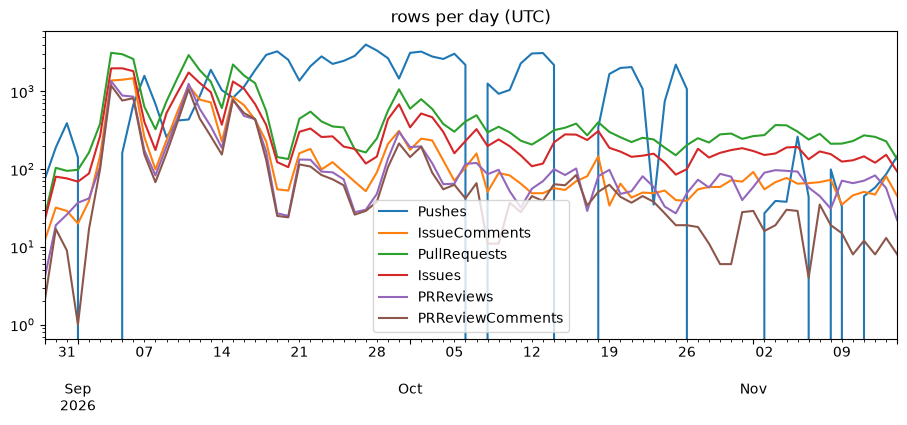

In [5]:
daily = pd.DataFrame({
    "Pushes": db["Pushes"]["created_at"].dt.floor("D").value_counts(),
    "IssueComments": db["IssueComments"]["created_at"].dt.floor("D").value_counts(),
    "PullRequests": db["PullRequests"]["first_seen_at"].dt.floor("D").value_counts(),
    "Issues": db["Issues"]["first_seen_at"].dt.floor("D").value_counts(),
    "PRReviews": db["PRReviews"]["first_seen_at"].dt.floor("D").value_counts(),
    "PRReviewComments": db["PRReviewComments"]["created_at"].dt.floor("D").value_counts(),
}).sort_index().fillna(0)

daily.plot(figsize=(11, 4), logy=True, title="rows per day (UTC)")
plt.show()

## 5. 計算一段時間內有多少活動

In [6]:
ACTIVITY = {
    "open_pr":           ("PullRequests",     "author_id",   "created_at"),
    "open_issue":        ("Issues",           "author_id",   "created_at"),
    "issue_comment":     ("IssueComments",    "author_id",   "created_at"),
    "pr_review":         ("PRReviews",        "reviewer_id", "submitted_at"),
    "pr_review_comment": ("PRReviewComments", "author_id",   "created_at"),
    "push":              ("Pushes",           "user_id",     "created_at"),
}
EVENT_COLS = list(ACTIVITY)

ROW_TIME = {
    "PullRequests": "first_seen_at", "Issues": "first_seen_at", "PRReviews": "first_seen_at",
    "IssueComments": "created_at", "PRReviewComments": "created_at", "Pushes": "created_at",
}


def activity_labels(db, t1, t2, user_ids):
    t1, t2 = pd.Timestamp(t1), pd.Timestamp(t2)
    users = db["Users"]
    out = pd.DataFrame({"UserID": list(user_ids)})
    for act, (table, who, when) in ACTIVITY.items():
        df = db[table]
        ok = (df[ROW_TIME[table]] < t2) & (df[when] >= t1) & (df[when] < t2)
        if act == "open_issue":
            ok &= ~df["is_pull_request"].fillna(False)   # 排除 Issue 中 PR 的討論串

        did = users.loc[users["user_id"].isin(df.loc[ok, who]), "github_user_id"]
        out[act] = out["UserID"].isin(did).astype(int)
    return out

## 6. Baseline: copy last week

資料最後一週有做的活動，就猜要預測的那週也會做。

In [7]:
def copy_last_week(db, data_end, user_ids): # baseline
    data_end = pd.Timestamp(data_end)
    return activity_labels(db, data_end - pd.Timedelta(days=7), data_end, user_ids)


week = pd.Timedelta(days=7)

val_weeks = pd.date_range("2026-09-12 16:00", "2026-11-07 16:00", freq="7D")
print("驗證週:", [str(v) for v in val_weeks])

rows = []
for v in val_weeks:
    data_end = v - week                                  # 可以用的資料只到這裡
    truth = activity_labels(db, v, v + week, test_ids)   # 這週的答案
    pred = copy_last_week(db, data_end, test_ids)        # 用 data_end 前一週來猜
    s = scores(pred, truth)
    row = {"week": v}
    for e in EVENT_COLS:
        row["pos_" + e] = truth[e].mean()
    row.update(macro_f1=s["macro_f1"], micro_f1=s["micro_f1"], score=s["score"])
    rows.append(row)

display(pd.DataFrame(rows).set_index("week").round(3))

驗證週: ['2026-09-12 16:00:00', '2026-09-19 16:00:00', '2026-09-26 16:00:00', '2026-10-03 16:00:00', '2026-10-10 16:00:00', '2026-10-17 16:00:00', '2026-10-24 16:00:00', '2026-10-31 16:00:00', '2026-11-07 16:00:00']


,pos_open_pr,pos_open_issue,pos_issue_comment,pos_pr_review,pos_pr_review_comment,pos_push,macro_f1,micro_f1,score
week,,,,,,,,,
2026-09-12 16:00:00,0.218,0.098,0.179,0.150,0.113,0.505,0.414,0.395,0.405
2026-09-19 16:00:00,0.098,0.056,0.075,0.071,0.055,0.542,0.376,0.420,0.398
2026-09-26 16:00:00,0.131,0.073,0.100,0.093,0.067,0.577,0.455,0.526,0.491
2026-10-03 16:00:00,0.104,0.055,0.071,0.070,0.034,0.469,0.392,0.516,0.454
2026-10-10 16:00:00,0.086,0.052,0.052,0.062,0.042,0.454,0.383,0.510,0.447
2026-10-17 16:00:00,0.077,0.049,0.047,0.049,0.038,0.394,0.360,0.483,0.421
2026-10-24 16:00:00,0.073,0.039,0.049,0.054,0.017,0.217,0.319,0.387,0.353
2026-10-31 16:00:00,0.082,0.042,0.056,0.061,0.024,0.060,0.297,0.266,0.281
2026-11-07 16:00:00,0.072,0.039,0.044,0.050,0.015,0.058,0.297,0.283,0.290


## 7. 模型 (GNN)

### 7.1 Snapshot：只留下某個時間點之前看得到的資料

In [8]:
ROW_TIME_ALL = {"Users": "first_seen_at", "Repositories": "first_seen_at", **ROW_TIME}


def snapshot(db, cutoff):
    cutoff = pd.Timestamp(cutoff)
    snap = {t: df[df[ROW_TIME_ALL[t]] < cutoff].copy() for t, df in db.items()}

    pr = snap["PullRequests"]
    not_merged = ~(pr["merged_at"] < cutoff)   # NaT 也算還沒 merge
    pr["merged_at"] = pr["merged_at"].mask(not_merged)
    pr["merged_by_id"] = pr["merged_by_id"].mask(not_merged)
    pr["closed_at"] = pr["closed_at"].mask(~(pr["closed_at"] < cutoff))

    iss = snap["Issues"]
    not_closed = ~(iss["closed_at"] < cutoff)
    iss["closed_at"] = iss["closed_at"].mask(not_closed)
    iss["state_reason"] = iss["state_reason"].mask(not_closed)

    rv = snap["PRReviews"]
    rv["dismissed_at"] = rv["dismissed_at"].mask(~(rv["dismissed_at"] < cutoff))
    return snap


# 檢查：用 END 切一次，看每張表剩多少、有沒有偷看到的時間
snap = snapshot(db, end)
for t in TABLES:
    print(f"{t:18s} {len(snap[t]):>10,} / {len(db[t]):>10,}")
for t, cols in [("PullRequests", ["merged_at", "closed_at"]), ("Issues", ["closed_at"]),
                ("PRReviews", ["dismissed_at"])]:
    for c in cols:
        assert not (snap[t][c] >= end).any(), (t, c)
print("沒有 >= cutoff 的時間")

Users                  10,378 /     10,378
Repositories           20,701 /     20,701
PullRequests           43,518 /     43,518
Issues                 28,222 /     28,222
IssueComments          15,764 /     15,764
PRReviews              13,019 /     13,019
PRReviewComments       10,145 /     10,145
Pushes                 89,903 /     89,903
沒有 >= cutoff 的時間


### 7.2 把資料庫變成圖 (RDL)

In [9]:
import numpy as np
import torch
from torch_geometric.data import HeteroData
import torch_geometric.transforms as T

DAY = pd.Timedelta(days=1)

# 節點：每張表一種節點，每一列一個節點
NODES = {
    "user":           ("Users",            "user_id"),
    "repo":           ("Repositories",     "repo_id"),
    "pr":             ("PullRequests",     "pr_id"),
    "issue":          ("Issues",           "issue_id"),
    "comment":        ("IssueComments",    "comment_id"),
    "review":         ("PRReviews",        "review_id"),
    "review_comment": ("PRReviewComments", "comment_id"),
    "push":           ("Pushes",           "push_id"),
}

# 邊：每個 FK 一種邊 (來源節點, FK 欄位, 目標節點)，之後再加反方向
EDGES = [
    ("pr", "repo_id", "repo"), ("pr", "author_id", "user"), ("pr", "merged_by_id", "user"),
    ("issue", "repo_id", "repo"), ("issue", "author_id", "user"), ("issue", "assignee_id", "user"),
    ("issue", "pull_request_id", "pr"),
    ("comment", "issue_id", "issue"), ("comment", "repo_id", "repo"), ("comment", "author_id", "user"),
    ("review", "pr_id", "pr"), ("review", "repo_id", "repo"), ("review", "reviewer_id", "user"),
    ("review_comment", "pr_id", "pr"), ("review_comment", "repo_id", "repo"),
    ("review_comment", "author_id", "user"), ("review_comment", "pull_request_review_id", "review"),
    ("review_comment", "in_reply_to_id", "review_comment"),
    ("push", "user_id", "user"), ("push", "repo_id", "repo"),
]


def time_enc(t, cutoff):
    # 時間編碼：離 cutoff 幾天 (沒有時間就當作 365 天前)
    d = ((cutoff - t) / DAY).fillna(365).clip(lower=0).to_numpy(float)
    return np.stack([np.log1p(d), np.exp(-d / 7), np.exp(-d / 30)], axis=1)


def dow_enc(t):
    # 台灣時間的星期幾，用 sin/cos 表示
    w = (t + pd.Timedelta(hours=8)).dt.day_of_week.fillna(0).to_numpy(float)
    return np.stack([np.sin(2 * np.pi * w / 7), np.cos(2 * np.pi * w / 7)], axis=1)


def flag(s):    # bool 欄位 -> 0/1
    return s.fillna(False).astype(float).to_numpy()[:, None]


def has(s):     # 有沒有值 -> 0/1
    return s.notna().to_numpy(float)[:, None]


def node_features(snap, c, use_time=True):
    if use_time:
        te = lambda t: time_enc(t, c)
        de = dow_enc
    else:   # 第 9 節的實驗用：時間特徵全部換成 0
        te = lambda t: np.zeros((len(t), 3))
        de = lambda t: np.zeros((len(t), 2))

    u, r, pr, iss = snap["Users"], snap["Repositories"], snap["PullRequests"], snap["Issues"]
    ic, rv, rc, ps = snap["IssueComments"], snap["PRReviews"], snap["PRReviewComments"], snap["Pushes"]
    feats = {
        "user": [flag(u["is_bot"]), flag(u["is_cohort"]), te(u["first_seen_at"])],
        "repo": [has(r["org_id"]), te(r["first_seen_at"])],
        "pr": [flag(pr["draft"]), flag(pr["is_cross_repo"]), has(pr["merged_at"]), has(pr["closed_at"]),
               te(pr["first_seen_at"]), te(pr["created_at"])],
        "issue": [flag(iss["is_pull_request"]), np.log1p(iss["num_labels"].fillna(0).to_numpy(float))[:, None],
                  has(iss["assignee_id"]), has(iss["milestone_title"]), has(iss["issue_type"]),
                  flag(iss["locked"]), has(iss["closed_at"]),
                  te(iss["first_seen_at"]), te(iss["created_at"])],
        "comment": [flag(ic["is_pull_request"]), has(ic["via_app"]),
                    te(ic["created_at"]), de(ic["created_at"])],
        "review": [(rv["state"] == s).fillna(False).to_numpy(float)[:, None]
                   for s in ["approved", "commented", "changes_requested"]]
                  + [has(rv["dismissed_at"]), te(rv["submitted_at"]), de(rv["submitted_at"])],
        "review_comment": [(rc["subject_type"] == "line").fillna(False).to_numpy(float)[:, None],
                           has(rc["in_reply_to_id"]), te(rc["created_at"]), de(rc["created_at"])],
        "push": [(ps["ref_type"] == "tag").fillna(False).to_numpy(float)[:, None], flag(ps["is_new_ref"]),
                 te(ps["created_at"]), de(ps["created_at"])],
    }
    return {k: torch.tensor(np.hstack(v), dtype=torch.float) for k, v in feats.items()}


def build_graph(db, cutoff, use_time=True, cross_table=True):
    cutoff = pd.Timestamp(cutoff)
    snap = snapshot(db, cutoff)
    g = HeteroData()
    for node, x in node_features(snap, cutoff, use_time).items():
        g[node].x = x

    # 第 9 節的實驗用：cross_table=False 只留「事件 -> user」的邊，user 看不到 repo / PR 那些跨表的關係
    edges = EDGES if cross_table else [e for e in EDGES if e[2] == "user"]

    # PK -> 節點編號 0..n-1
    index = {node: pd.Series(np.arange(len(snap[t])), index=snap[t][pk].to_numpy())
             for node, (t, pk) in NODES.items()}
    for src, col, dst in edges:
        fk = snap[NODES[src][0]][col].to_numpy(dtype=float, na_value=np.nan)
        dst_idx = index[dst].reindex(fk).to_numpy()   # 不在 snapshot 裡的會變 NaN
        ok = ~np.isnan(dst_idx)
        g[src, col, dst].edge_index = torch.tensor(np.vstack([np.arange(len(fk))[ok], dst_idx[ok]]),
                                                   dtype=torch.long)
    g = T.ToUndirected()(g)   # 每種邊都加上反方向，讓資訊可以傳回 user

    g["user"].gid = torch.tensor(snap["Users"]["github_user_id"].to_numpy(dtype="int64"))
    g["user"].cohort = torch.tensor(snap["Users"]["is_cohort"].fillna(False).to_numpy(bool))
    return g


def graph_labels(db, g, cutoff):
    # 預測 cutoff + 7 天開始的那一週 (中間空 7 天，跟正式預測一樣)
    v = pd.Timestamp(cutoff) + week
    y = activity_labels(db, v, v + week, g["user"].gid.numpy())
    return torch.tensor(y[EVENT_COLS].to_numpy(), dtype=torch.float)


# 檢查：用 10/24 當 cutoff 建一張圖
g = build_graph(db, "2026-10-24 16:00")
for node in g.node_types:
    print(f"{node:15s} {g[node].num_nodes:>7,} 個節點, 特徵 {g[node].x.shape[1]} 維")
print("邊的種類:", len(g.edge_types), "(含反方向)")
y = graph_labels(db, g, "2026-10-24 16:00")
print("cohort 使用者的正例比例:", dict(zip(EVENT_COLS, y[g["user"].cohort].mean(0).numpy().round(3))))

user              9,765 個節點, 特徵 5 維
repo             19,285 個節點, 特徵 4 維
pr               38,167 個節點, 特徵 10 維
issue            25,057 個節點, 特徵 13 維
comment          14,483 個節點, 特徵 7 維
review           11,657 個節點, 特徵 9 維
review_comment    9,782 個節點, 特徵 7 維
push             85,418 個節點, 特徵 7 維
邊的種類: 39 (含反方向)
cohort 使用者的正例比例: {'open_pr': np.float32(0.071), 'open_issue': np.float32(0.036), 'issue_comment': np.float32(0.049), 'pr_review': np.float32(0.053), 'pr_review_comment': np.float32(0.02), 'push': np.float32(0.053)}


### 7.3 GNN 模型

In [10]:
from torch import nn
from torch_geometric.nn import SAGEConv, HeteroConv

HIDDEN = 64
EPOCHS = 40


class GNN(nn.Module):
    def __init__(self, g, aggr="sum"):
        super().__init__()
        # 每種節點的特徵維度不一樣，先各自用一層 Linear 變成 64 維
        self.enc = nn.ModuleDict({n: nn.Linear(g[n].x.shape[1], HIDDEN) for n in g.node_types})
        # 2 層 message passing，每種邊有自己的 SAGEConv；sum 才保留「做了幾次」的資訊
        self.convs = nn.ModuleList([
            HeteroConv({et: SAGEConv(HIDDEN, HIDDEN, aggr=aggr) for et in g.edge_types}, aggr="sum")
            for _ in range(2)])
        self.norms = nn.ModuleList([
            nn.ModuleDict({n: nn.LayerNorm(HIDDEN) for n in g.node_types}) for _ in range(2)])
        # user 節點 -> 6 種活動
        self.head = nn.Sequential(nn.Linear(HIDDEN, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, 6))

    def forward(self, g):
        h = {n: self.enc[n](g[n].x) for n in g.node_types}
        for conv, norm in zip(self.convs, self.norms):
            out = conv(h, g.edge_index_dict)
            # 加回自己 (residual)；沒有收到任何訊息的節點種類就只有自己
            h = {n: torch.relu(norm[n](out.get(n, 0) + h[n])) for n in h}
        return self.head(h["user"])


def train_gnn(graphs, aggr="sum"):
    torch.manual_seed(0)   # 固定亂數，結果才能重現
    model = GNN(graphs[0], aggr)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3, weight_decay=1e-5)
    loss_fn = nn.BCEWithLogitsLoss()
    for ep in range(1, EPOCHS + 1):
        model.train()
        for g in graphs:   # 每個 cutoff 的圖輪流訓練
            m = g["user"].cohort   # 只用 cohort 使用者算 loss
            opt.zero_grad()
            loss = loss_fn(model(g)[m], g["user"].y[m])
            loss.backward()
            opt.step()
    return model


def predict_proba(model, g, user_ids):
    # 回傳每個 user 6 種活動的機率；不在圖裡的 user (cutoff 前完全沒出現) 機率當 0
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(g)).numpy()
    p = pd.DataFrame(p, columns=EVENT_COLS)
    p["UserID"] = g["user"].gid.numpy()
    return pd.DataFrame({"UserID": list(user_ids)}).merge(p, on="UserID", how="left").fillna(0)


def to_binary(proba, thr):
    out = proba[["UserID"]].copy()
    for e in EVENT_COLS:
        out[e] = (proba[e] >= thr[e]).astype(int)
    return out


def best_thresholds(proba, truth):
    # 評分是 F1，所以每種活動各自找讓 F1 最大的門檻 (不是直接用 0.5)
    thr = {}
    for e in EVENT_COLS:
        y = truth[e].to_numpy() == 1
        best_f1, best_t = -1, 0.5
        for t in np.arange(0.02, 0.9, 0.01):
            p = proba[e].to_numpy() >= t
            f1 = 2 * (p & y).sum() / (p.sum() + y.sum() + 1e-9)
            if f1 > best_f1:
                best_f1, best_t = f1, round(float(t), 2)
        thr[e] = best_t
    return thr


# 每個 cutoff 建一張圖：特徵用 cutoff 前的資料，標籤是 cutoff+7天 開始那週
def make_graphs(cutoffs, **graph_opts):
    graphs = []
    for c in cutoffs:
        g = build_graph(db, c, **graph_opts)
        g["user"].y = graph_labels(db, g, c)
        graphs.append(g)
    return graphs

### 7.4 驗證：walk-forward

只用一週驗證太不穩 (一週 4,465 人，正例又少)，所以往後滾動，每週都照「真正預測時的流程」做一次：

假設資料只到 `data_end`，要預測 `data_end + 7 天` 開始那週：
1. 訓練：cutoff 9/5 ~ `data_end - 14 天` 的圖 (標籤週最晚剛好在 `data_end` 結束，不會用到之後的答案)
2. 調門檻：在最後一個訓練 cutoff 上調 (它的標籤週 = 資料的最後一週)
3. 預測：在 `data_end` 建圖，預測後面隔 7 天的那週

| data_end | 訓練 cutoff | 預測週 (UTC) |
|---|---|---|
| 10/10 | 9/5 ~ 9/26 (4 張圖) | 10/17 |
| 10/17 | 9/5 ~ 10/3 (5 張圖) | 10/24 |
| 10/24 | 9/5 ~ 10/10 (6 張圖) | 10/31 |
| 10/31 | 9/5 ~ 10/17 (7 張圖) | 11/7 |

GNN             預測週 10/17  score 0.462  (227s)
GNN             預測週 10/24  score 0.378  (267s)
GNN             預測週 10/31  score 0.322  (340s)
GNN             預測週 11/07  score 0.358  (477s)


,10/17,10/24,10/31,11/07,mean
model,,,,,
copy_last_week,0.421,0.353,0.281,0.290,0.336
GNN,0.462,0.378,0.322,0.358,0.380


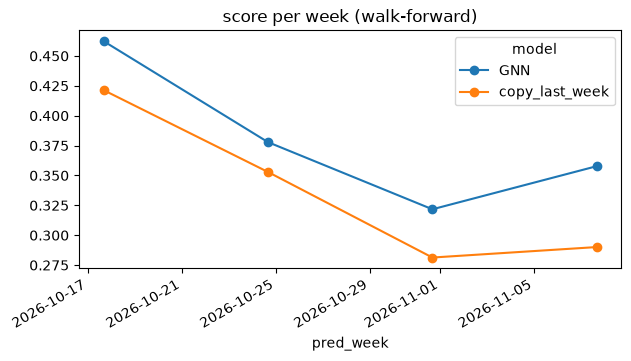

In [11]:
FIRST_CUT = pd.Timestamp("2026-09-05 16:00")   # 第一個訓練 cutoff (前面只有 1 週資料)


def run_once(data_end, aggr="sum", **graph_opts):
    # 模擬「資料只到 data_end」的整個流程，回傳 data_end+7天 那週的機率和門檻
    data_end = pd.Timestamp(data_end)
    cuts = pd.date_range(FIRST_CUT, data_end - 2 * week, freq="7D")   # 標籤週最晚在 data_end 結束
    model = train_gnn(make_graphs(cuts, **graph_opts), aggr)

    last = cuts[-1]   # 用最後一個訓練 cutoff 調門檻
    thr = best_thresholds(predict_proba(model, build_graph(db, last, **graph_opts), test_ids),
                          activity_labels(db, last + week, last + 2 * week, test_ids))

    proba = predict_proba(model, build_graph(db, data_end, **graph_opts), test_ids)
    return proba, thr


def score_row(name, c, pred, truth):
    s = scores(pred, truth)
    return {"model": name, "pred_week": c + week, "macro_f1": s["macro_f1"],
            "micro_f1": s["micro_f1"], "score": s["score"]}


saved = {}   # 存每週的機率


def walk_forward(name, **opts):
    rows = []
    for c in test_cuts:
        t0 = time.time()
        proba, thr = run_once(c, **opts)
        truth = activity_labels(db, c + week, c + 2 * week, test_ids)
        saved[name, c] = (proba, thr, truth)
        rows.append(score_row(name, c, to_binary(proba, thr), truth))
        print(f"{name:15s} 預測週 {c + week:%m/%d}  score {rows[-1]['score']:.3f}  ({time.time() - t0:.0f}s)")
    return rows


def show(rows):
    t = pd.DataFrame(rows).pivot(index="model", columns="pred_week", values="score")
    t.columns = [f"{d:%m/%d}" for d in t.columns]
    t["mean"] = t.mean(axis=1)
    display(t.sort_values("mean").round(3))


test_cuts = pd.date_range("2026-10-10 16:00", "2026-10-31 16:00", freq="7D")   # data_end，預測週 10/17 ~ 11/7

rows = []
for c in test_cuts:
    truth = activity_labels(db, c + week, c + 2 * week, test_ids)
    rows.append(score_row("copy_last_week", c, copy_last_week(db, c, test_ids), truth))
rows += walk_forward("GNN")

show(rows)
pd.DataFrame(rows).pivot(index="pred_week", columns="model", values="score").plot(
    marker="o", figsize=(7, 3.5), title="score per week (walk-forward)")
plt.show()

## 8. 輸出預測

`data_end = END` (TW 11/15)：
- 訓練：cutoff 9/5 ~ 10/31 (9 張圖，標籤週 9/12 ~ 11/7)
- 門檻：在 10/31 那張圖上調 (標籤週 = 資料的最後一週 11/7 ~ 11/14)
- 預測：在 END 建圖，預測 TW 11/22 ~ 11/29 那週

門檻每次都在「最近一週」重新調，因為資料的分布一直在變 (例如 10/24 之後 push 幾乎消失，有 push 的比例約 50% → 6%)。

In [12]:
t0 = time.time()
proba, final_thr = run_once(end)
print(f"花了 {time.time() - t0:.0f} 秒")
print("門檻:", final_thr)

pred = to_binary(proba, final_thr)
out_file = out_dir / OUTPUT
pred.to_csv(out_file, index=False)
print("存到", out_file)
print("預測會做的比例:")
print(pred[EVENT_COLS].mean().round(3))

# 用 evaluate.py 檢查格式
!"{sys.executable}" scripts/evaluate.py --pred "{out_file}" --input submission/test_input.csv

花了 797 秒
門檻: {'open_pr': 0.16, 'open_issue': 0.26, 'issue_comment': 0.22, 'pr_review': 0.24, 'pr_review_comment': 0.26, 'push': 0.34}
存到 work\outputs\output.csv
預測會做的比例:
open_pr              0.107
open_issue           0.031
issue_comment        0.045
pr_review            0.034
pr_review_comment    0.007
push                 0.024
dtype: float64
Format check: no errors (4465 users)


## 9. 額外實驗

全部用 walk-forward (4 個預測週)，每次只改一個地方，看分數變多少：

| 名稱 | 改了什麼 | 想看什麼 |
|---|---|---|
| `GNN_no_time` | 時間編碼 (`time_enc`, `dow_enc`) 全部換成 0 | 時間資訊有沒有用|
| `GNN_mean` | 鄰居用平均 (mean) 聚合，不用加總 (sum) | 「做了幾次」有沒有用  |
| `GNN_user_only` | 只留「事件 → user」的邊，拿掉 repo、PR↔review 等跨表的邊 | 跨表關係有沒有用|
| `GNN_thr_0.5` | 門檻全部用 0.5 | 調門檻有沒有用 |
| `GNN_thr_fixed` | 門檻只在第一週 (data_end 10/10) 調一次，之後都沿用 | 每週重調門檻有沒有用|


In [13]:
exp_rows = list(rows)   # copy_last_week 和 GNN

exp_rows += walk_forward("GNN_no_time", use_time=False)
exp_rows += walk_forward("GNN_mean", aggr="mean")
exp_rows += walk_forward("GNN_user_only", cross_table=False)

first_thr = saved["GNN", test_cuts[0]][1]
for c in test_cuts:
    proba, thr, truth = saved["GNN", c]
    exp_rows.append(score_row("GNN_thr_0.5", c, to_binary(proba, {e: 0.5 for e in EVENT_COLS}), truth))
    exp_rows.append(score_row("GNN_thr_fixed", c, to_binary(proba, first_thr), truth))

show(exp_rows)

GNN_no_time     預測週 10/17  score 0.440  (353s)
GNN_no_time     預測週 10/24  score 0.348  (257s)
GNN_no_time     預測週 10/31  score 0.292  (237s)
GNN_no_time     預測週 11/07  score 0.306  (253s)
GNN_mean        預測週 10/17  score 0.424  (59s)
GNN_mean        預測週 10/24  score 0.320  (86s)
GNN_mean        預測週 10/31  score 0.258  (104s)
GNN_mean        預測週 11/07  score 0.218  (179s)
GNN_user_only   預測週 10/17  score 0.460  (33s)
GNN_user_only   預測週 10/24  score 0.373  (54s)
GNN_user_only   預測週 10/31  score 0.312  (65s)
GNN_user_only   預測週 11/07  score 0.363  (80s)


,10/17,10/24,10/31,11/07,mean
model,,,,,
GNN_thr_0.5,0.403,0.352,0.212,0.156,0.281
GNN_mean,0.424,0.320,0.258,0.218,0.305
copy_last_week,0.421,0.353,0.281,0.290,0.336
GNN_no_time,0.440,0.348,0.292,0.306,0.346
GNN_thr_fixed,0.462,0.375,0.332,0.337,0.376
GNN_user_only,0.460,0.373,0.312,0.363,0.377
GNN,0.462,0.378,0.322,0.358,0.380
